# UNIT 5: OBJECT RECOGNITION

## Task 3: Object Recognition Using Viola-Jones and YOLO

### Objective
The objective of this experiment is to compare two object detection techniques:

1. Haar Cascade Classifier using the Viola-Jones method.
2. YOLO (You Only Look Once) pretrained object detection model.

The experiment will display detected objects using bounding boxes, class labels and confidence scores wherever applicable.


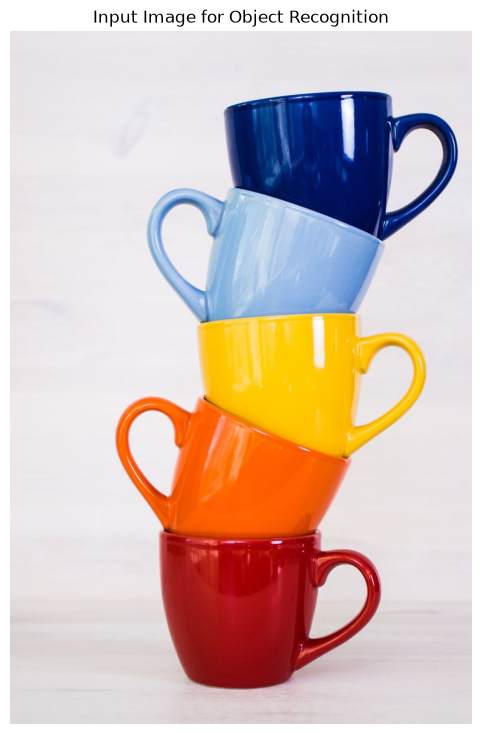

Image loaded successfully!
Image dimensions: (1104, 736, 3)


In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from ultralytics import YOLO

# Project paths
PROJECT_DIR = Path.cwd()
IMAGE_PATH = PROJECT_DIR / "dataset" / "images" / "original.jpg"

# Load image
image = cv2.imread(str(IMAGE_PATH))

if image is None:
    raise FileNotFoundError(f"Image not found: {IMAGE_PATH}")

# Convert BGR to RGB
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Display image
plt.figure(figsize=(7, 9))
plt.imshow(image_rgb)
plt.title("Input Image for Object Recognition")
plt.axis("off")
plt.show()

print("Image loaded successfully!")
print("Image dimensions:", image.shape)

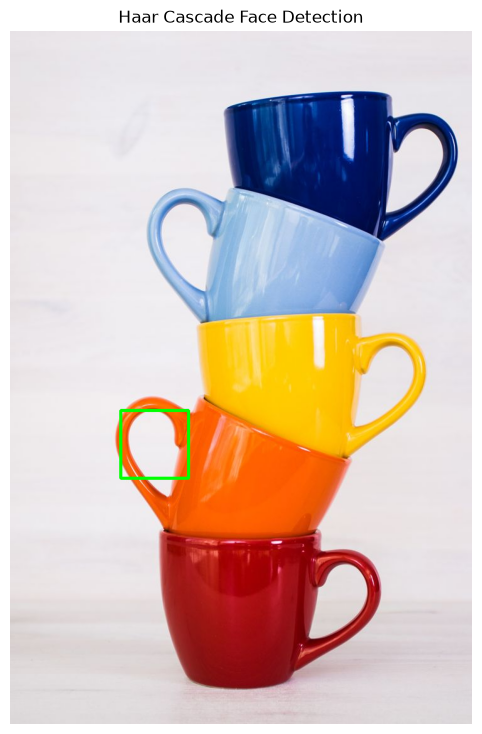

Number of faces detected: 1
Haar Cascade detection completed!


In [2]:
# Haar Cascade Face Detection

# Load pretrained face detection model
haar_path = (
    cv2.data.haarcascades +
    "haarcascade_frontalface_default.xml"
)

face_cascade = cv2.CascadeClassifier(haar_path)

# Convert image to grayscale
gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Detect faces
faces = face_cascade.detectMultiScale(
    gray_image,
    scaleFactor=1.1,
    minNeighbors=5,
    minSize=(30, 30)
)

# Draw bounding boxes around detected faces
haar_output = image.copy()

for (x, y, w, h) in faces:
    cv2.rectangle(
        haar_output,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        3
    )

# Display result
plt.figure(figsize=(8, 9))
plt.imshow(cv2.cvtColor(haar_output, cv2.COLOR_BGR2RGB))
plt.title("Haar Cascade Face Detection")
plt.axis("off")
plt.show()

print("Number of faces detected:", len(faces))
print("Haar Cascade detection completed!")

In [11]:
from pathlib import Path
import cv2

# Create output folder
output_dir = Path("outputs/task3")
output_dir.mkdir(parents=True, exist_ok=True)

# Save Haar Cascade detection image
cv2.imwrite(
    str(output_dir / "haar_face_detection.jpg"),
    haar_output
)

print("Haar Cascade output saved successfully!")
print("File:", output_dir / "haar_face_detection.jpg")

Haar Cascade output saved successfully!
File: outputs\task3\haar_face_detection.jpg


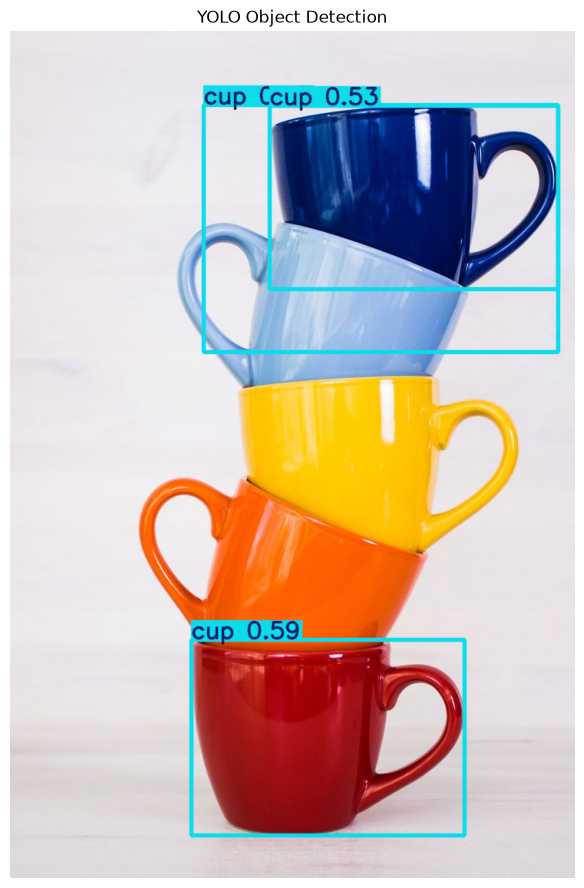

YOLO Detection Results:
Object: cup | Confidence: 59.07 %
Object: cup | Confidence: 53.33 %
Object: cup | Confidence: 43.47 %
YOLO detection completed!


In [3]:
# YOLO Object Detection

from ultralytics import YOLO

# Load pretrained YOLO model
model = YOLO("yolov8n.pt")

# Perform object detection
results = model.predict(
    source=image,
    conf=0.25,
    verbose=False
)

# Draw bounding boxes and labels
yolo_output = results[0].plot()

# Display detection result
plt.figure(figsize=(9, 11))
plt.imshow(cv2.cvtColor(yolo_output, cv2.COLOR_BGR2RGB))
plt.title("YOLO Object Detection")
plt.axis("off")
plt.show()

# Print detected objects
print("YOLO Detection Results:")

for box in results[0].boxes:
    class_id = int(box.cls[0])
    confidence = float(box.conf[0])

    print(
        "Object:", model.names[class_id],
        "| Confidence:", round(confidence * 100, 2), "%"
    )

print("YOLO detection completed!")

In [12]:
from pathlib import Path
import pandas as pd
import cv2

# Create output folder
output_dir = Path("outputs/task3")
output_dir.mkdir(parents=True, exist_ok=True)

# Save YOLO detection image
cv2.imwrite(
    str(output_dir / "yolo_object_detection.jpg"),
    yolo_output
)

# Store detected object details
detection_data = []

for box in results[0].boxes:
    class_id = int(box.cls[0])
    confidence = float(box.conf[0])

    detection_data.append({
        "Object": model.names[class_id],
        "Confidence (%)": round(confidence * 100, 2)
    })

# Create and save detection table
yolo_df = pd.DataFrame(detection_data)

display(yolo_df)

yolo_df.to_csv(
    output_dir / "yolo_detection_results.csv",
    index=False
)

print("YOLO output image and detection results saved successfully!")

,Object,Confidence (%)
0,cup,59.07
1,cup,53.33
2,cup,43.47


YOLO output image and detection results saved successfully!


In [13]:
import pandas as pd
from pathlib import Path

# Haar Cascade vs YOLO Comparison

comparison_data = {
    "Parameter": [
        "Algorithm",
        "Technology",
        "Primary purpose",
        "Objects detected",
        "Detection count",
        "False detection / Limitation",
        "Result"
    ],

    "Haar Cascade": [
        "Viola-Jones",
        "Traditional Machine Learning",
        "Face Detection",
        "Face-like patterns",
        str(len(faces)),
        "Cup handle incorrectly detected as a face",
        "False positive in this experiment"
    ],

    "YOLO": [
        "You Only Look Once",
        "Deep Learning",
        "Object Detection",
        "Multiple object categories",
        str(len(results[0].boxes)),
        "Some cups were missed and bounding boxes overlapped",
        "Detected 3 cups in this experiment"
    ]
}

comparison_df = pd.DataFrame(comparison_data)

display(comparison_df)

# Save comparison table
output_dir = Path("outputs/task3")
output_dir.mkdir(parents=True, exist_ok=True)

comparison_df.to_csv(
    output_dir / "haar_vs_yolo_comparison.csv",
    index=False
)

print("Haar Cascade and YOLO comparison completed!")
print("Comparison CSV saved successfully!")

,Parameter,Haar Cascade,YOLO
0,Algorithm,Viola-Jones,You Only Look Once
1,Technology,Traditional Machine Learning,Deep Learning
2,Primary purpose,Face Detection,Object Detection
3,Objects detected,Face-like patterns,Multiple object categories
4,Detection count,1,3
5,False detection / Limitation,Cup handle incorrectly detected as a face,Some cups were missed and bounding boxes overl...
6,Result,False positive in this experiment,Detected 3 cups in this experiment


Haar Cascade and YOLO comparison completed!
Comparison CSV saved successfully!


## Conclusion

In this experiment, two object detection techniques, Haar Cascade and YOLOv8, were implemented using OpenCV and Python.

Haar Cascade was used for face detection. However, it incorrectly identified a cup handle as a face, resulting in a false positive.

YOLOv8 was used for general object detection. It successfully detected three cups in the input image, although some cups were missed and some bounding boxes overlapped.

The experiment demonstrates that Haar Cascade is suitable for specific detection tasks, while YOLOv8 supports multiple object categories using deep learning. Both techniques have limitations depending on the input image and detection conditions.

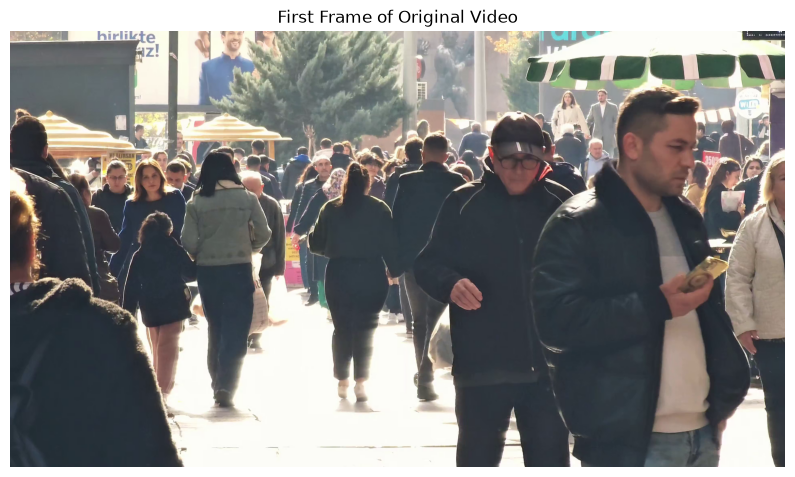

Video loaded successfully!
Video resolution: 3840 x 2160
Frames per second: 60.0
Total frames: 1020
Video duration: 17.0 seconds


True

In [7]:
# Step 1: Load and inspect video

import cv2
import matplotlib.pyplot as plt
from pathlib import Path

# Video file path
VIDEO_PATH = Path("dataset/videos/original_video.mp4")

# Check whether video exists
if not VIDEO_PATH.exists():
    raise FileNotFoundError(f"Video not found: {VIDEO_PATH}")

# Open video
cap = cv2.VideoCapture(str(VIDEO_PATH))

if not cap.isOpened():
    raise RuntimeError("Unable to open video file!")

# Read video properties
fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

duration = total_frames / fps if fps > 0 else 0

# Read first frame
ret, first_frame = cap.read()

if not ret:
    raise RuntimeError("Unable to read the first video frame!")

# Display first frame
first_frame_rgb = cv2.cvtColor(
    first_frame,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(10, 6))
plt.imshow(first_frame_rgb)
plt.title("First Frame of Original Video")
plt.axis("off")
plt.show()

# Print video information
print("Video loaded successfully!")
print("Video resolution:", width, "x", height)
print("Frames per second:", fps)
print("Total frames:", total_frames)
print("Video duration:", round(duration, 2), "seconds")

# Reset video to beginning
cap.set(cv2.CAP_PROP_POS_FRAMES, 0)

In [14]:
import pandas as pd
from pathlib import Path
import cv2

# Create Task 4 output folder
output_dir = Path("outputs/task4")
output_dir.mkdir(parents=True, exist_ok=True)

# Save the first frame
cv2.imwrite(
    str(output_dir / "video_first_frame.jpg"),
    first_frame
)

# Store video information
video_info = pd.DataFrame({
    "Parameter": [
        "Video Resolution",
        "Frames Per Second",
        "Total Frames",
        "Duration (seconds)"
    ],
    "Value": [
        f"{width} x {height}",
        fps,
        total_frames,
        round(duration, 2)
    ]
})

display(video_info)

# Save video information
video_info.to_csv(
    output_dir / "video_information.csv",
    index=False
)

print("First frame and video information saved successfully!")

,Parameter,Value
0,Video Resolution,3840 x 2160
1,Frames Per Second,60.0
2,Total Frames,1020
3,Duration (seconds),17.0


First frame and video information saved successfully!


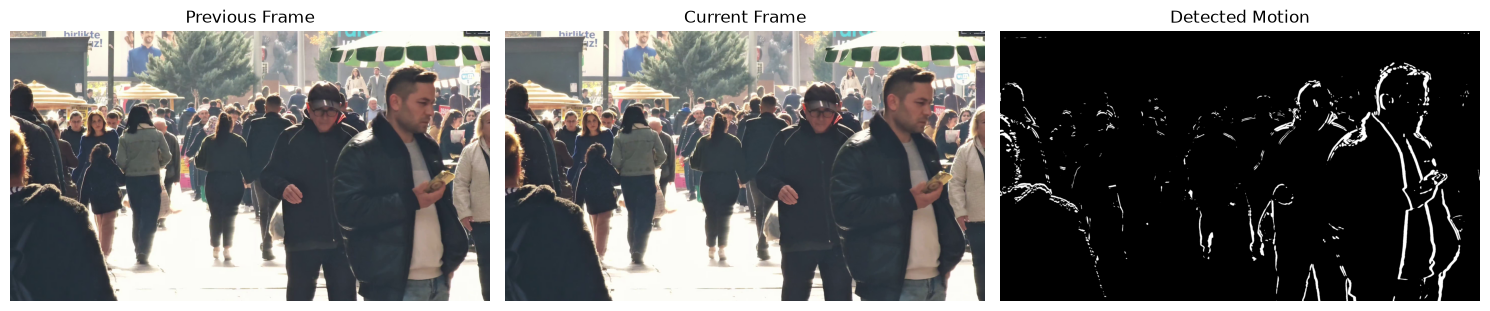

Frame differencing outputs saved successfully!
Frame differencing completed successfully!


In [15]:
# Frame Differencing for Motion Detection

cap.set(cv2.CAP_PROP_POS_FRAMES, 0)

ret, previous_frame = cap.read()

if not ret:
    raise ValueError("Could not read the first frame")

previous_gray = cv2.cvtColor(
    previous_frame, cv2.COLOR_BGR2GRAY
)

previous_gray = cv2.GaussianBlur(
    previous_gray, (21, 21), 0
)

ret, current_frame = cap.read()

if not ret:
    raise ValueError("Could not read the next frame")

current_gray = cv2.cvtColor(
    current_frame, cv2.COLOR_BGR2GRAY
)

current_gray = cv2.GaussianBlur(
    current_gray, (21, 21), 0
)

# Calculate difference between frames
frame_difference = cv2.absdiff(
    previous_gray, current_gray
)

# Apply threshold
_, motion_mask = cv2.threshold(
    frame_difference, 25, 255, cv2.THRESH_BINARY
)

# Display results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(previous_frame, cv2.COLOR_BGR2RGB))
plt.title("Previous Frame")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cv2.cvtColor(current_frame, cv2.COLOR_BGR2RGB))
plt.title("Current Frame")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(motion_mask, cmap="gray")
plt.title("Detected Motion")
plt.axis("off")

plt.tight_layout()

# Save the complete comparison figure
plt.savefig(
    output_dir / "frame_differencing.jpg",
    dpi=300,
    bbox_inches="tight"
)

# Save individual images
cv2.imwrite(
    str(output_dir / "previous_frame.jpg"),
    previous_frame
)

cv2.imwrite(
    str(output_dir / "current_frame.jpg"),
    current_frame
)

cv2.imwrite(
    str(output_dir / "motion_mask.jpg"),
    motion_mask
)

plt.show()

print("Frame differencing outputs saved successfully!")

print("Frame differencing completed successfully!")


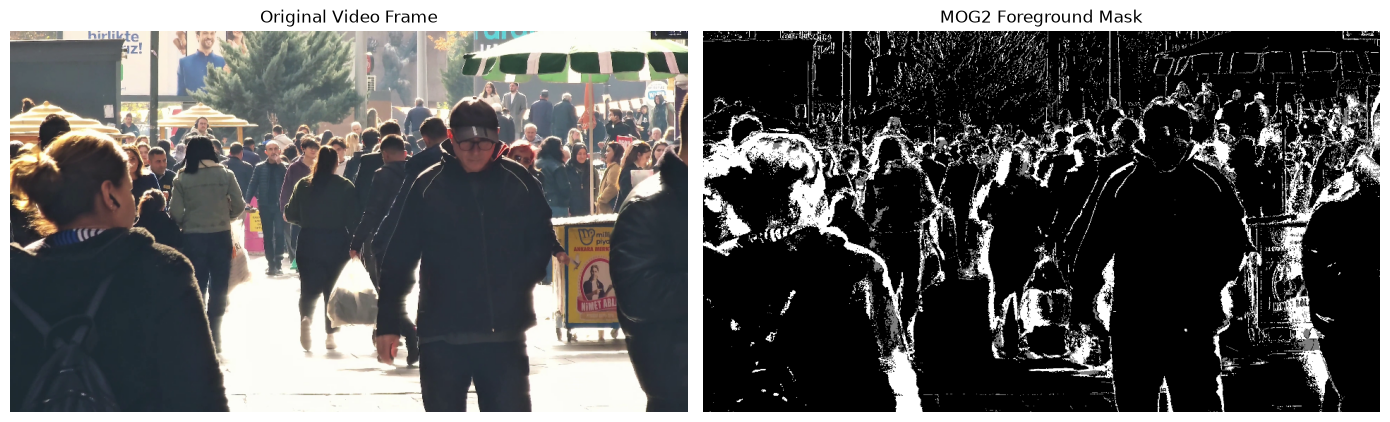

MOG2 output images saved successfully!


,Parameter,Value
0,Algorithm,MOG2
1,History,500
2,Variance Threshold,25
3,Detect Shadows,True
4,Frames Processed,90


MOG2 experiment information saved successfully!
MOG2 Background Subtraction completed!
Frames processed: 90


True

In [18]:
# MOG2 Background Subtraction

# Create MOG2 background subtractor
back_sub = cv2.createBackgroundSubtractorMOG2(
    history=500,
    varThreshold=25,
    detectShadows=True
)

# Reset video to beginning
cap.set(cv2.CAP_PROP_POS_FRAMES, 0)

frame_count = 0
max_frames = 90

while frame_count < max_frames:

    ret, frame = cap.read()

    if not ret:
        break

    # Resize frame for faster processing
    frame = cv2.resize(frame, (960, 540))

    # Apply background subtraction
    foreground_mask = back_sub.apply(frame)

    frame_count += 1

# Display final frame and foreground mask
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
plt.title("Original Video Frame")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(foreground_mask, cmap="gray")
plt.title("MOG2 Foreground Mask")
plt.axis("off")

plt.tight_layout()

# Save comparison figure
plt.savefig(
    output_dir / "mog2_background_subtraction.jpg",
    dpi=300,
    bbox_inches="tight"
)

# Save original processed frame
cv2.imwrite(
    str(output_dir / "mog2_original_frame.jpg"),
    frame
)

# Save foreground mask
cv2.imwrite(
    str(output_dir / "mog2_foreground_mask.jpg"),
    foreground_mask
)

plt.show()

print("MOG2 output images saved successfully!")
# Save MOG2 experiment details
mog2_info = pd.DataFrame({
    "Parameter": [
        "Algorithm",
        "History",
        "Variance Threshold",
        "Detect Shadows",
        "Frames Processed"
    ],
    "Value": [
        "MOG2",
        500,
        25,
        True,
        frame_count
    ]
})

display(mog2_info)

mog2_info.to_csv(
    output_dir / "mog2_results.csv",
    index=False
)

print("MOG2 experiment information saved successfully!")

# Reset video
cap.set(cv2.CAP_PROP_POS_FRAMES, 0)

print("MOG2 Background Subtraction completed!")
print("Frames processed:", frame_count)

# Reset video for the next experiment
cap.set(cv2.CAP_PROP_POS_FRAMES, 0)

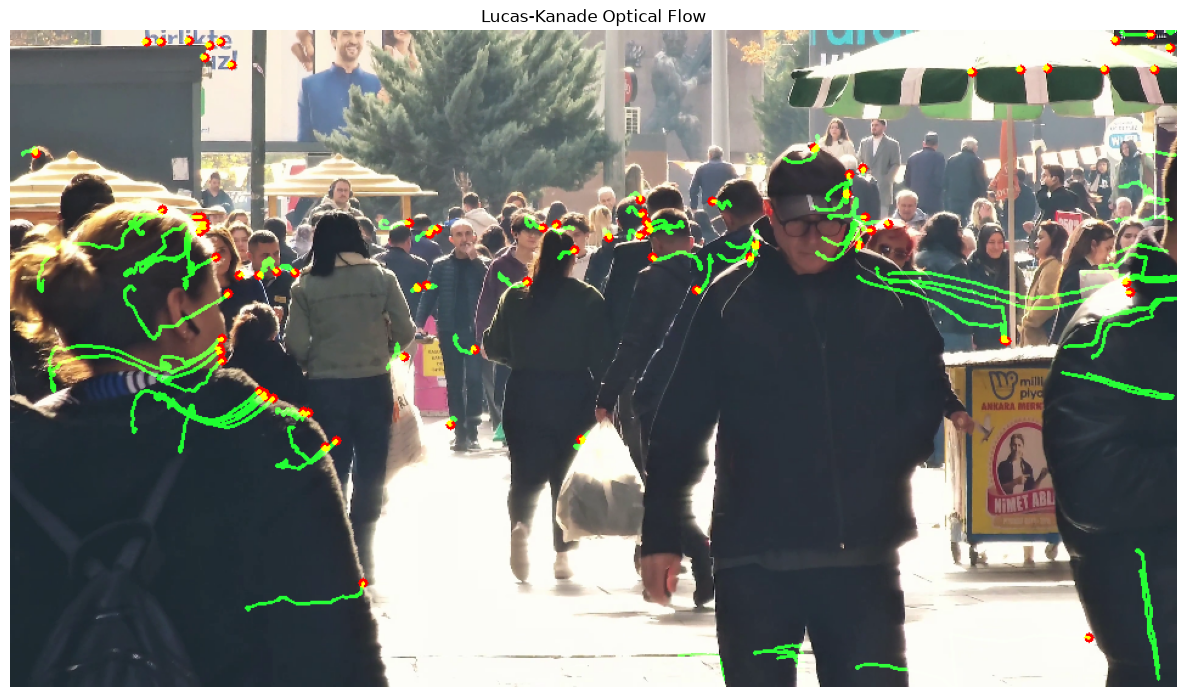

Lucas-Kanade output saved successfully!
Lucas-Kanade Optical Flow completed!
Frames processed: 90
Tracked feature points: 80


True

In [16]:
# Lucas-Kanade Optical Flow

# Parameters for detecting feature points
feature_params = dict(
    maxCorners=100,
    qualityLevel=0.3,
    minDistance=7,
    blockSize=7
)

# Parameters for Lucas-Kanade optical flow
lk_params = dict(
    winSize=(15, 15),
    maxLevel=2,
    criteria=(
        cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT,
        10,
        0.03
    )
)

# Reset video
cap.set(cv2.CAP_PROP_POS_FRAMES, 0)

# Read first frame
ret, old_frame = cap.read()

if not ret:
    raise ValueError("Unable to read video!")

old_frame = cv2.resize(old_frame, (960, 540))
old_gray = cv2.cvtColor(old_frame, cv2.COLOR_BGR2GRAY)

# Detect feature points
p0 = cv2.goodFeaturesToTrack(
    old_gray,
    mask=None,
    **feature_params
)

# Create mask for drawing motion trails
mask = np.zeros_like(old_frame)

frame_count = 0
max_frames = 90

while frame_count < max_frames:

    ret, frame = cap.read()

    if not ret:
        break

    frame = cv2.resize(frame, (960, 540))
    frame_gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    # Calculate optical flow
    p1, st, err = cv2.calcOpticalFlowPyrLK(
        old_gray,
        frame_gray,
        p0,
        None,
        **lk_params
    )

    if p1 is None:
        break

    # Select successfully tracked points
    good_new = p1[st.flatten() == 1]
    good_old = p0[st.flatten() == 1]

    # Draw motion lines and points
    for new, old in zip(good_new, good_old):

        a, b = new.ravel().astype(int)
        c, d = old.ravel().astype(int)

        mask = cv2.line(mask, (a, b), (c, d), (0, 255, 0), 2)

        frame = cv2.circle(
            frame,
            (a, b),
            4,
            (0, 0, 255),
            -1
        )

    output = cv2.add(frame, mask)

    old_gray = frame_gray.copy()
    p0 = good_new.reshape(-1, 1, 2)

    frame_count += 1

# Display final optical flow result
# Display and save optical flow result
plt.figure(figsize=(12, 7))

plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
plt.title("Lucas-Kanade Optical Flow")
plt.axis("off")

plt.tight_layout()

# Save output image
cv2.imwrite(
    str(output_dir / "lucas_kanade_optical_flow.jpg"),
    output
)

plt.savefig(
    output_dir / "lucas_kanade_optical_flow_comparison.jpg",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Lucas-Kanade output saved successfully!")

print("Lucas-Kanade Optical Flow completed!")
print("Frames processed:", frame_count)
print("Tracked feature points:", len(good_new))

# Reset video
cap.set(cv2.CAP_PROP_POS_FRAMES, 0)

In [19]:
import pandas as pd
from pathlib import Path

# Comparison of motion detection techniques

motion_comparison = {
    "Parameter": [
        "Technique",
        "Working Principle",
        "Main Output",
        "Advantages",
        "Limitations",
        "Application"
    ],

    "Frame Differencing": [
        "Frame Differencing",
        "Compares consecutive video frames",
        "Binary motion mask",
        "Simple and fast",
        "Sensitive to lighting changes and camera movement",
        "Basic motion detection"
    ],

    "MOG2": [
        "Background Subtraction",
        "Separates foreground from learned background",
        "Foreground mask",
        "Can detect moving objects against a stationary background",
        "May classify shadows and background changes as foreground",
        "Surveillance and people tracking"
    ],

    "Lucas-Kanade": [
        "Optical Flow",
        "Tracks feature points between frames",
        "Motion vectors and tracking trails",
        "Shows direction and movement of feature points",
        "Depends on successfully detected and tracked features",
        "Motion tracking and video analysis"
    ]
}

motion_comparison_df = pd.DataFrame(motion_comparison)

display(motion_comparison_df)

# Save comparison table
output_dir = Path("outputs/task4")
output_dir.mkdir(parents=True, exist_ok=True)

motion_comparison_df.to_csv(
    output_dir / "motion_detection_comparison.csv",
    index=False
)

print("Motion detection comparison saved successfully!")

,Parameter,Frame Differencing,MOG2,Lucas-Kanade
0,Technique,Frame Differencing,Background Subtraction,Optical Flow
1,Working Principle,Compares consecutive video frames,Separates foreground from learned background,Tracks feature points between frames
2,Main Output,Binary motion mask,Foreground mask,Motion vectors and tracking trails
3,Advantages,Simple and fast,Can detect moving objects against a stationary...,Shows direction and movement of feature points
4,Limitations,Sensitive to lighting changes and camera movement,May classify shadows and background changes as...,Depends on successfully detected and tracked f...
5,Application,Basic motion detection,Surveillance and people tracking,Motion tracking and video analysis


Motion detection comparison saved successfully!


## Comparison of Motion Detection Techniques

### 1. Frame Differencing
Frame differencing detects motion by comparing two consecutive video frames. The differences between the frames highlight moving regions. It is simple and computationally efficient, but sensitive to lighting changes and camera movement.

### 2. MOG2 Background Subtraction
MOG2 uses a Gaussian Mixture Model to learn the background and separate foreground objects. It detects moving people and other foreground regions. It can also identify shadows, but may produce noise in complex backgrounds.

### 3. Lucas-Kanade Optical Flow
Lucas-Kanade Optical Flow tracks feature points between consecutive frames and estimates their movement. Green lines represent motion trails, while red points indicate tracked feature positions. It provides information about the direction of movement.

### Comparison Table

| Parameter | Frame Differencing | MOG2 | Lucas-Kanade |
|---|---|---|---|
| Technique | Frame comparison | Background subtraction | Feature tracking |
| Input | Consecutive frames | Video frames | Consecutive grayscale frames |
| Output | Motion mask | Foreground mask | Motion vectors and points |
| Main purpose | Detect frame changes | Separate foreground | Track movement |
| Advantage | Simple and fast | Detects moving regions | Shows movement direction |
| Limitation | Sensitive to lighting changes | May detect shadows/noise | Requires trackable feature points |

### Conclusion

All three techniques were successfully implemented using OpenCV. Frame differencing identified changes between consecutive frames, MOG2 separated foreground regions from the background, and Lucas-Kanade tracked feature points across video frames.

These experiments demonstrate how computer vision techniques can detect and analyze movement in real-world video footage.

## Conclusion

In this experiment, three computer vision techniques were implemented for video motion estimation: Frame Differencing, MOG2 Background Subtraction, and Lucas-Kanade Optical Flow.

Frame Differencing identified motion by calculating the difference between consecutive video frames.

MOG2 Background Subtraction separated foreground objects from the background by learning background patterns over time.

Lucas-Kanade Optical Flow tracked feature points between consecutive frames and visualized their movement using motion trails.

The experiment demonstrated that each technique has a different approach to motion detection and tracking. Frame Differencing is simple, MOG2 is useful for foreground extraction, and Lucas-Kanade provides information about the direction and movement of tracked points.